In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import os
import socket
import json
import base64

In [3]:
from sklearn.metrics import mean_squared_error
import math

In [4]:
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import Convolution2D
from keras.models import Sequential, load_model
from keras.callbacks import ModelCheckpoint
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from keras.layers import  MaxPooling2D

In [5]:
dataset = pd.read_csv('Dataset/FloodDataset.csv')
dataset.fillna(0, inplace = True)

In [6]:
dataset.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,water_level
0,KERALA,1901,28.7,44.7,51.6,160.0,174.7,824.6,743.0,357.5,197.7,266.9,350.8,48.4,3248.6
1,KERALA,1902,6.7,2.6,57.3,83.9,134.5,390.9,1205.0,315.8,491.6,358.4,158.3,121.5,3326.6
2,KERALA,1903,3.2,18.6,3.1,83.6,249.7,558.6,1022.5,420.2,341.8,354.1,157.0,59.0,3271.2
3,KERALA,1904,23.7,3.0,32.2,71.5,235.7,1098.2,725.5,351.8,222.7,328.1,33.9,3.3,3129.7
4,KERALA,1905,1.2,22.3,9.4,105.9,263.3,850.2,520.5,293.6,217.2,383.5,74.4,0.2,2741.6


In [7]:
norm1 = MinMaxScaler(feature_range = (0, 1))
norm2 = MinMaxScaler(feature_range = (0, 1))

In [8]:
dataset = dataset.values
X = dataset[:,2:dataset.shape[1]-1]
Y = dataset[:,dataset.shape[1]-1]

In [10]:
df = pd.DataFrame(X)
df

,0,1,2,3,4,5,6,7,8,9,10,11
0,28.7,44.7,51.6,160,174.7,824.6,743,357.5,197.7,266.9,350.8,48.4
1,6.7,2.6,57.3,83.9,134.5,390.9,1205,315.8,491.6,358.4,158.3,121.5
2,3.2,18.6,3.1,83.6,249.7,558.6,1022.5,420.2,341.8,354.1,157,59
3,23.7,3,32.2,71.5,235.7,1098.2,725.5,351.8,222.7,328.1,33.9,3.3
4,1.2,22.3,9.4,105.9,263.3,850.2,520.5,293.6,217.2,383.5,74.4,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...
110,20.5,45.7,24.1,165.2,124.2,788.5,536.8,492.7,391.2,227.2,169.7,49.5
111,7.4,11,21,171.1,95.3,430.3,362.6,501.6,241.1,187.5,112.9,9.4
112,3.9,40.1,49.9,49.3,119.3,1042.7,830.2,369.7,318.6,259.9,154.9,17
113,4.6,10.3,17.9,95.7,251,454.4,677.8,733.9,298.8,355.5,99.5,47.2


In [11]:

indices = np.arange(X.shape[0])
np.random.shuffle(indices)
X = X[indices]
Y = Y[indices]
Y = Y.reshape(-1, 1)
X  = norm1.fit_transform(X)
Y = norm2.fit_transform(Y)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2)

In [13]:
accuracy = []
mse = []
rmse = []

In [14]:
def calculateMetrics(algorithm, predict, test_labels):
    predict = norm2.inverse_transform(np.abs(predict))
    test_label = norm2.inverse_transform(test_labels)
    mse_value = mean_squared_error(test_label, predict)
    rmse_value = math.sqrt(mse_value)
    predict = predict.ravel()
    test_label = test_label.ravel()
    acc = 100 - rmse_value
    mse.append(mse_value)
    rmse.append(rmse_value)
    accuracy.append(acc)
    plt.plot(test_label, color = 'red', label = 'True Water Level')
    plt.plot(predict, color = 'green', label = 'Predicted Water Level')
    plt.title(algorithm+' Water Level Prediction')
    plt.xlabel('Test Data')
    plt.ylabel('Predicted Water Level')
    plt.legend()
    plt.show() 

In [31]:
ML_Model = []
mse = []
rmse = []


#function to call for storing the results
def storeResults(model, a,b):
    ML_Model.append(model)
    mse.append(round(a, 3))
    rmse.append(round(b, 3))

# FFNN

In [16]:
model = Sequential()
model.add(Dense(32,  input_shape=(X.shape[1],)))
model.add(Dense(16, activation="relu"))
model.add(Dense(units=1))
model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [17]:
hist = model.fit(X_train, y_train, epochs = 80, batch_size = 2, validation_data=(X_test, y_test),verbose=1)

Epoch 1/80
46/46 [==============================] - 10s 9ms/step - loss: 0.1469 - val_loss: 0.0424
Epoch 2/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0346 - val_loss: 0.0244
Epoch 3/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0192 - val_loss: 0.0184
Epoch 4/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0142 - val_loss: 0.0208
Epoch 5/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0142 - val_loss: 0.0174
Epoch 6/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0090 - val_loss: 0.0154
Epoch 7/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0086 - val_loss: 0.0145
Epoch 8/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0074 - val_loss: 0.0147
Epoch 9/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0063 - val_loss: 0.0131
Epoch 10/80
46/46 [==============================] - 0s 2ms/step - loss: 0.0060 - val_loss: 0.0104
Epoch 11/80
46/46 

Epoch 80/80
46/46 [==============================] - 0s 2ms/step - loss: 2.1766e-06 - val_loss: 3.4375e-04


In [18]:
predict = model.predict(X_test)

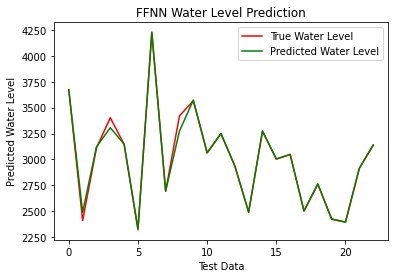

In [19]:
calculateMetrics("FFNN", predict, y_test)

In [20]:
mse_ffn = mean_squared_error(predict, y_test)
rmse_ffn = math.sqrt(mse_ffn)

In [32]:
storeResults('FFNN',mse_ffn,rmse_ffn)

# Extension CNN2D

In [22]:
X_train1 = X_train.reshape(X_train.shape[0],X_train.shape[1], 1, 1)
X_test1 = X_test.reshape(X_test.shape[0],X_test.shape[1], 1, 1)

In [23]:
extension_model = Sequential()
extension_model.add(Convolution2D(32, 1, 1, input_shape = (X_train1.shape[1], X_train1.shape[2], X_train1.shape[3]), activation = 'relu'))
extension_model.add(MaxPooling2D(pool_size = (1, 1)))
extension_model.add(Convolution2D(16, 1, 1, activation = 'relu'))
extension_model.add(MaxPooling2D(pool_size = (1, 1)))
extension_model.add(Flatten())
extension_model.add(Dense(28, activation = 'relu'))
extension_model.add(Dense(1))
extension_model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [24]:
his1 = extension_model.fit(X_train1, y_train, epochs = 80, batch_size = 2, validation_data=(X_test1, y_test), verbose=1)

Epoch 1/80
46/46 [==============================] - 3s 7ms/step - loss: 0.0573 - val_loss: 0.0274
Epoch 2/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0165 - val_loss: 0.0197
Epoch 3/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0100 - val_loss: 0.0181
Epoch 4/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0080 - val_loss: 0.0217
Epoch 5/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0085 - val_loss: 0.0088
Epoch 6/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0032 - val_loss: 0.0068
Epoch 7/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0032 - val_loss: 0.0055
Epoch 8/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0021 - val_loss: 0.0037
Epoch 9/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0012 - val_loss: 0.0040
Epoch 10/80
46/46 [==============================] - 0s 3ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 11/80
46/46 [

46/46 [==============================] - 0s 3ms/step - loss: 1.1960e-04 - val_loss: 5.8691e-04
Epoch 80/80
46/46 [==============================] - 0s 3ms/step - loss: 9.9541e-05 - val_loss: 3.1759e-04


In [25]:
predict = extension_model.predict(X_test1)

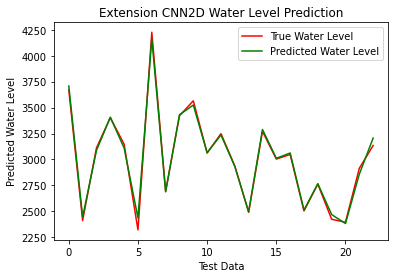

In [26]:
calculateMetrics("Extension CNN2D", predict, y_test)

In [27]:
mse_cnn = mean_squared_error(predict, y_test)
rmse_cnn = math.sqrt(mse_cnn)

In [33]:
storeResults('Extension CNN',mse_cnn,rmse_cnn)

Comparison

In [34]:
#creating dataframe
import pandas as pd
result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'MSE' : mse,
                       'RMSE': rmse,
                      
                      })

In [35]:
result

,ML Model,MSE,RMSE
0,FFNN,0.0,0.019
1,Extension CNN,0.0,0.018
